## 1. Ask Phase
* **Business Task:** Examine how operational factors (`length`, `power`, `engine_age`, `dist`, `patch_area`), spatial/temporal attributes (`landing`, `patch`, `month`, `year`), and environmental variables (`surf_temp`, `nao_index`) relate to catch weight (`weight`) and inflation-adjusted catch value (`value_cpi`).
* **Stakeholders:** Fisheries managers, commercial vessel operators, marine equipment suppliers, and portfolio reviewers.
* **Key Metrics:** `weight`, `value_cpi`, `value`, `price`, `y_`, `length`, `power`, `engine_age`, `dist`, `patch_area`, `surf_temp`, and `nao_index`.

## 2. Prepare Phase
* **Source Files:** `full_dataset.csv` and `raster.csv` located in `/kaggle/input/datasets/alexanderbader/fishing-data-north-atlantic/`.
* **Dataset Scope:** `full_dataset.csv` contains `1,601,870` rows and `22` columns.

### Data Provenance and Reuse

This is an independent educational portfolio analysis of a compiled public dataset. It is not commissioned by or endorsed by the data publishers.

Compilation: Alexander Bader, Fishing Data North Atlantic, https://www.kaggle.com/datasets/alexanderbader/fishing-data-north-atlantic . The Kaggle page labels the compilation CC0 and links this source summary: https://raw.githubusercontent.com/ambader/aa_map/main/data_summary.pdf .

The summary identifies catch and vessel data from Fiskeridirektoratet, the Norwegian Directorate of Fisheries, alongside environmental and geographic inputs. Source raw data: Fiskeridirektoratet. The publisher's reuse conditions require attribution under the Norwegian Licence for Open Government Data (NLOD): https://www.fiskeridir.no/statistikk-tall-og-analyse/lisens-for-bruk-av-fiskeridirektoratets-data . License reference: https://data.norge.no/nlod/en/1.0 . Original source category: https://www.fiskeridir.no/statistikk-tall-og-analyse/data-og-statistikk-om-yrkesfiske/apne-data-fangstdata-seddel-koblet-med-fartoydata .

This analysis loads the compilation into SQLite, filters invalid negative measures, groups records and produces aggregate comparisons and charts. These transformations and interpretations are the portfolio author's work, not recommendations by the original publishers. The CC0 compilation label is not presented as removing rights or conditions belonging to upstream sources.

The compilation summary also references sea-surface-temperature, NOAA and geocoding inputs. One referenced SST product is openly shared by NASA Earthdata: https://www.earthdata.nasa.gov/data/catalog/pocloud-amsre-remss-l3u-v7a-7a . The precise provenance and historic terms for every environmental/geocoding component have not been fully verified. OpenCage's current terms require respecting the licenses of returned results: https://opencagedata.com/terms . Its source list is at https://opencagedata.com/credits .

This repository should link to the compilation and official sources rather than rehost the compiled raw dataset while those details remain unresolved. The notebook's code license does not override upstream data terms.


In [1]:
import os
import pandas as pd

path = (
    '/kaggle/input/datasets/alexanderbader/fishing-data-north-atlantic/full_dataset.csv'
)
print('File exists:', os.path.exists(path))

df = pd.read_csv(path)
print('Shape (rows, cols):', df.shape)
print('Columns:', df.columns.tolist())

File exists: True
Shape (rows, cols): (1601870, 22)
Columns: ['y_', 'ID', 'engine_age', 'length', 'power', 'month', 'landing', 'weight', 'value', 'value_cpi', 'price', 'y_month', 'year', 'patch', 'dist', 'patch_area', 'weight_lym', 'weight_lm', 'val_lm', 'val_lym', 'nao_index', 'surf_temp']


## 3. Process Phase
Validate data quality, inspect missing values, and create a clean SQL table (`fishing_clean`) before running analysis queries.

In [2]:
print('Missing values:\n', df.isnull().sum()[df.isnull().sum() > 0])
print('\nData types:\n', df.dtypes)

Missing values:
 surf_temp    128348
dtype: int64

Data types:
 y_            float64
ID              int64
engine_age    float64
length        float64
power         float64
month           int64
landing        object
weight        float64
value         float64
value_cpi     float64
price         float64
y_month         int64
year          float64
patch          object
dist          float64
patch_area      int64
weight_lym    float64
weight_lm     float64
val_lm        float64
val_lym       float64
nao_index     float64
surf_temp     float64
dtype: object


In [3]:
import sqlite3

conn = sqlite3.connect(':memory:')
df.to_sql('fishing', conn, index=False, if_exists='replace')


def sql(q):
  return pd.read_sql_query(q, conn)


conn.execute('DROP TABLE IF EXISTS fishing_clean;')
conn.execute("""
CREATE TABLE fishing_clean AS
SELECT *
FROM fishing
WHERE COALESCE(weight, 0) >= 0
  AND COALESCE(value_cpi, 0) >= 0
  AND COALESCE(price, 0) >= 0
  AND COALESCE(dist, 0) >= 0;
""")

sql('SELECT COUNT(*) AS clean_rows FROM fishing_clean;')

,clean_rows
0,1601677


## 4. Analyze Phase (SQL)
Run focused SQL queries across landing ports, vessel size, engine age, and sea surface temperature.

In [4]:
sql("""
SELECT
    landing,
    COUNT(*) AS total_rows,
    ROUND(AVG(weight), 2) AS avg_weight,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
GROUP BY landing
HAVING COUNT(*) >= 100
ORDER BY avg_value_cpi DESC
LIMIT 10;
""")

,landing,total_rows,avg_weight,avg_value_cpi
0,FLORA,4446,48549.45,282208.15
1,HAREID,3784,44238.24,251857.24
2,ØRSTA,1384,7553.19,210884.50
3,EIGERSUND,24278,96240.27,196989.46
4,SELJE,3980,27027.46,183952.07
5,ØRLAND,3856,25107.60,132073.73
6,SULA,8742,21355.62,124779.07
7,VÅGSØY,37088,43320.96,114885.77
8,AUSTEVOLL,8208,20285.09,113414.58
9,LØDINGEN,6682,26762.01,112168.43


In [5]:
sql("""
SELECT
    CASE
        WHEN length < 15 THEN 'Small (<15m)'
        WHEN length BETWEEN 15 AND 28 THEN 'Medium (15-28m)'
        ELSE 'Large (>28m)'
    END AS vessel_size_group,
    COUNT(*) AS total_rows,
    ROUND(AVG(power), 1) AS avg_power,
    ROUND(AVG(dist), 1) AS avg_dist,
    ROUND(AVG(weight), 2) AS avg_weight,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
GROUP BY vessel_size_group
ORDER BY avg_value_cpi DESC;
""")

,vessel_size_group,total_rows,avg_power,avg_dist,avg_weight,avg_value_cpi
0,Large (>28m),157328,3250.7,616.5,62089.79,221294.17
1,Medium (15-28m),183330,603.7,409.6,5990.12,29194.63
2,Small (<15m),1261019,148.0,374.8,257.27,2891.70


In [6]:
sql("""
SELECT
    CASE
        WHEN engine_age < 10 THEN 'Newer (<10 yrs)'
        WHEN engine_age BETWEEN 10 AND 25 THEN 'Mid-Age (10-25 yrs)'
        ELSE 'Older (>25 yrs)'
    END AS engine_age_group,
    COUNT(*) AS total_rows,
    ROUND(AVG(weight), 2) AS avg_weight,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
WHERE engine_age IS NOT NULL
GROUP BY engine_age_group
ORDER BY avg_value_cpi DESC;
""")

,engine_age_group,total_rows,avg_weight,avg_value_cpi
0,Newer (<10 yrs),247588,18600.45,62503.74
1,Mid-Age (10-25 yrs),605473,7858.85,32911.07
2,Older (>25 yrs),748616,2441.15,11237.50


In [7]:
sql("""
SELECT
    CASE
        WHEN surf_temp < 278 THEN 'Cold (<278K)'
        WHEN surf_temp BETWEEN 278 AND 284 THEN 'Moderate (278-284K)'
        ELSE 'Warmer (>284K)'
    END AS temp_band,
    COUNT(*) AS valid_temp_rows,
    ROUND(AVG(weight), 2) AS avg_weight,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
WHERE surf_temp IS NOT NULL
GROUP BY temp_band
ORDER BY avg_value_cpi DESC;
""")

,temp_band,valid_temp_rows,avg_weight,avg_value_cpi
0,Cold (<278K),110185,4965.94,44204.45
1,Warmer (>284K),307438,8247.62,34342.39
2,Moderate (278-284K),1055706,6603.00,23807.92


## 5. Share Phase
Key findings and visual comparisons generated directly from `fishing_clean` SQL queries.

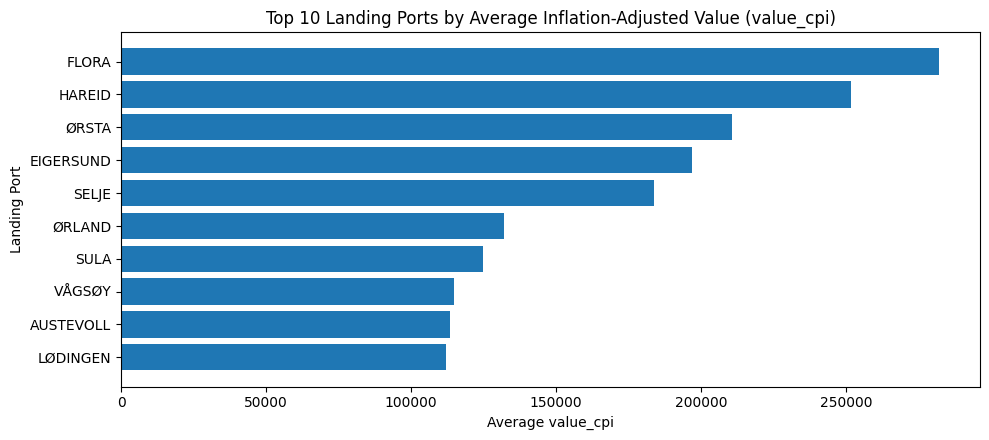

In [8]:
import matplotlib.pyplot as plt

df_ports = sql("""
SELECT
    landing,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
GROUP BY landing
HAVING COUNT(*) >= 100
ORDER BY avg_value_cpi DESC
LIMIT 10;
""")

plt.figure(figsize=(10, 4.5))
plt.barh(df_ports['landing'][::-1], df_ports['avg_value_cpi'][::-1])
plt.title('Top 10 Landing Ports by Average Inflation-Adjusted Value (value_cpi)')
plt.xlabel('Average value_cpi')
plt.ylabel('Landing Port')
plt.tight_layout()
plt.show()

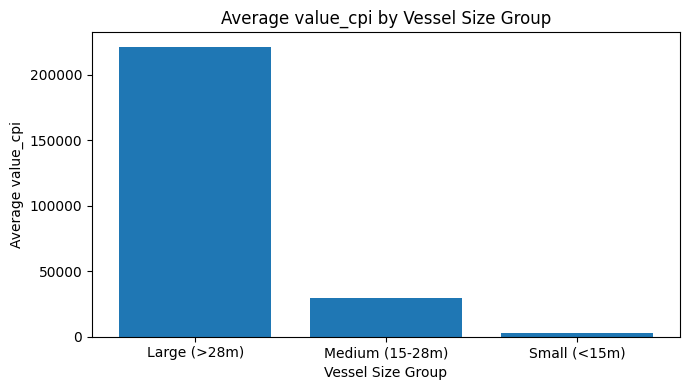

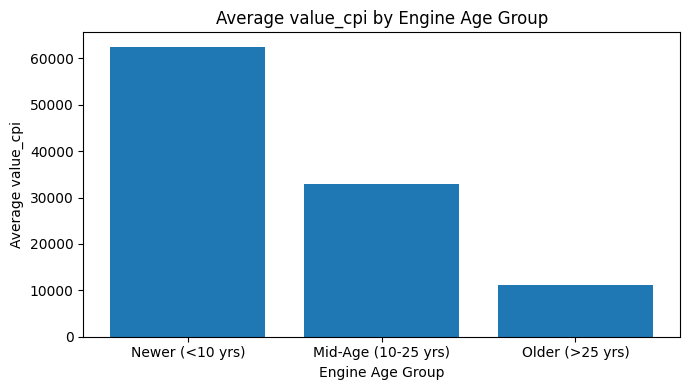

In [9]:
df_size = sql("""
SELECT
    CASE
        WHEN length < 15 THEN 'Small (<15m)'
        WHEN length BETWEEN 15 AND 28 THEN 'Medium (15-28m)'
        ELSE 'Large (>28m)'
    END AS vessel_size_group,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
GROUP BY vessel_size_group
ORDER BY avg_value_cpi DESC;
""")

plt.figure(figsize=(7, 4))
plt.bar(df_size['vessel_size_group'], df_size['avg_value_cpi'])
plt.title('Average value_cpi by Vessel Size Group')
plt.xlabel('Vessel Size Group')
plt.ylabel('Average value_cpi')
plt.tight_layout()
plt.show()

df_engine = sql("""
SELECT
    CASE
        WHEN engine_age < 10 THEN 'Newer (<10 yrs)'
        WHEN engine_age BETWEEN 10 AND 25 THEN 'Mid-Age (10-25 yrs)'
        ELSE 'Older (>25 yrs)'
    END AS engine_age_group,
    ROUND(AVG(value_cpi), 2) AS avg_value_cpi
FROM fishing_clean
WHERE engine_age IS NOT NULL
GROUP BY engine_age_group
ORDER BY avg_value_cpi DESC;
""")

plt.figure(figsize=(7, 4))
plt.bar(df_engine['engine_age_group'], df_engine['avg_value_cpi'])
plt.title('Average value_cpi by Engine Age Group')
plt.xlabel('Engine Age Group')
plt.ylabel('Average value_cpi')
plt.tight_layout()
plt.show()

## 6. Act Phase
* **Interpretation:** The aggregate comparisons describe associations between vessel characteristics, environmental measures and catch outcomes. They do not establish that engine age, vessel size or temperature causes the differences.
* **Possible Follow-up:** Investigate maintenance and fleet-planning hypotheses with controls for fishing effort, species, location, year and vessel characteristics before recommending investments or operational changes.
* **Next Steps:** Explore `raster.csv`, calendar months and year trends, and `value_cpi / weight` where `weight > 0`. On any rerun, record the input file name, compilation version and actual access date, rather than inventing missing metadata.
